# Neural Networks: Theory Notebook

This notebook makes neural-network math executable: forward passes, backprop, activations, initialization, optimization, normalization, dropout, and diagnostics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Affine layer and ReLU

In [2]:
X = np.array([[1.0, -2.0], [0.5, 1.0]])
W = np.array([[0.2, -0.4], [1.0, 0.5], [-0.3, 0.8]])
b = np.array([0.1, -0.2, 0.3])
Z = X @ W.T + b
H = np.maximum(0, Z)
print("Z:\n", np.round(Z, 3))
print("ReLU(H):\n", np.round(H, 3))

Z:
 [[ 1.1  -0.2  -1.6 ]
 [-0.2   0.8   0.95]]
ReLU(H):
 [[1.1  0.   0.  ]
 [0.   0.8  0.95]]


## 2. Two-layer forward pass

In [3]:
rng = np.random.default_rng(1)
X = rng.normal(size=(4, 3))
W1 = rng.normal(scale=0.5, size=(5, 3))
b1 = np.zeros(5)
W2 = rng.normal(scale=0.5, size=(2, 5))
b2 = np.zeros(2)
H = np.maximum(0, X @ W1.T + b1)
logits = H @ W2.T + b2
print("hidden shape:", H.shape)
print("logits shape:", logits.shape)

hidden shape: (4, 5)
logits shape: (4, 2)


## 3. Softmax cross-entropy

In [4]:
logits = np.array([[2.0, 1.0, -1.0], [0.1, 0.2, 0.3]])
targets = np.array([0, 2])
shifted = logits - logits.max(axis=1, keepdims=True)
probs = np.exp(shifted) / np.exp(shifted).sum(axis=1, keepdims=True)
loss = -np.log(probs[np.arange(len(targets)), targets]).mean()
print("probs:\n", np.round(probs, 3))
print("loss:", loss)

probs:
 [[0.705 0.259 0.035]
 [0.301 0.332 0.367]]
loss: 0.6754775324987152


## 4. Backprop through affine layer

In [5]:
X = rng.normal(size=(3, 4))
W = rng.normal(size=(2, 4))
dZ = rng.normal(size=(3, 2))
dW = dZ.T @ X
db = dZ.sum(axis=0)
dX = dZ @ W
print("dW shape:", dW.shape)
print("db shape:", db.shape)
print("dX shape:", dX.shape)

dW shape: (2, 4)
db shape: (2,)
dX shape: (3, 4)


## 5. ReLU derivative

In [6]:
z = np.array([-2.0, 0.0, 3.0])
relu = np.maximum(0, z)
drelu = (z > 0).astype(float)
print("relu:", relu)
print("derivative convention:", drelu)

relu: [0. 0. 3.]
derivative convention: [0. 0. 1.]


## 6. Finite-difference gradient check

In [7]:
x = np.array([1.0, -2.0])
w = np.array([0.3, 0.7])
y = 1.5
def loss(wv):
    pred = wv @ x
    return 0.5 * (pred - y) ** 2
analytic = (w @ x - y) * x
eps = 1e-6
numeric = np.zeros_like(w)
for i in range(len(w)):
    e = np.zeros_like(w)
    e[i] = eps
    numeric[i] = (loss(w + e) - loss(w - e)) / (2 * eps)
print("analytic:", analytic)
print("numeric:", numeric)
print("max error:", np.max(np.abs(analytic - numeric)))

analytic: [-2.6  5.2]
numeric: [-2.6  5.2]
max error: 2.583018243740298e-10


## 7. Initialization scale

In [8]:
fan_in, fan_out = 256, 512
xavier_std = np.sqrt(2 / (fan_in + fan_out))
he_std = np.sqrt(2 / fan_in)
print("Xavier std:", xavier_std)
print("He std:", he_std)

Xavier std: 0.05103103630798288
He std: 0.08838834764831845


## 8. Activation variance through depth

In [9]:
rng = np.random.default_rng(2)
B, d, depth = 512, 256, 20
for name, std in [("too small", 0.02), ("He", np.sqrt(2/d)), ("too large", 0.2)]:
    h = rng.normal(size=(B, d))
    variances = []
    for _ in range(depth):
        W = rng.normal(scale=std, size=(d, d))
        h = np.maximum(0, h @ W.T)
        variances.append(h.var())
    print(name, "final variance:", variances[-1])

too small final variance: 1.534487483680829e-26
He final variance: 1.6587327073248286
too large final variance: 187078323544316.47


## 9. SGD with momentum

In [10]:
theta = np.array([2.0, -1.0])
v = np.zeros_like(theta)
beta = 0.9
lr = 0.1
for step in range(5):
    grad = theta
    v = beta * v + grad
    theta = theta - lr * v
    print(step, np.round(theta, 4))

0 [ 1.8 -0.9]
1 [ 1.44 -0.72]
2 [ 0.972 -0.486]
3 [ 0.4536 -0.2268]
4 [-0.0583  0.0292]


## 10. Dropout with inverted scaling

In [11]:
rng = np.random.default_rng(3)
h = np.ones(10)
p_drop = 0.3
mask = (rng.random(size=h.shape) > p_drop).astype(float)
h_drop = h * mask / (1 - p_drop)
print("mask:", mask.astype(int))
print("mean after inverted dropout:", h_drop.mean())

mask: [0 0 1 1 0 1 1 0 1 0]
mean after inverted dropout: 0.7142857142857143


## 11. LayerNorm

In [12]:
x = np.array([[1.0, 2.0, 4.0], [2.0, 2.0, 2.0]])
mean = x.mean(axis=1, keepdims=True)
var = x.var(axis=1, keepdims=True)
y = (x - mean) / np.sqrt(var + 1e-5)
print("LayerNorm:\n", np.round(y, 4))

LayerNorm:
 [[-1.069  -0.2673  1.3363]
 [ 0.      0.      0.    ]]


## 12. Train/validation diagnostic

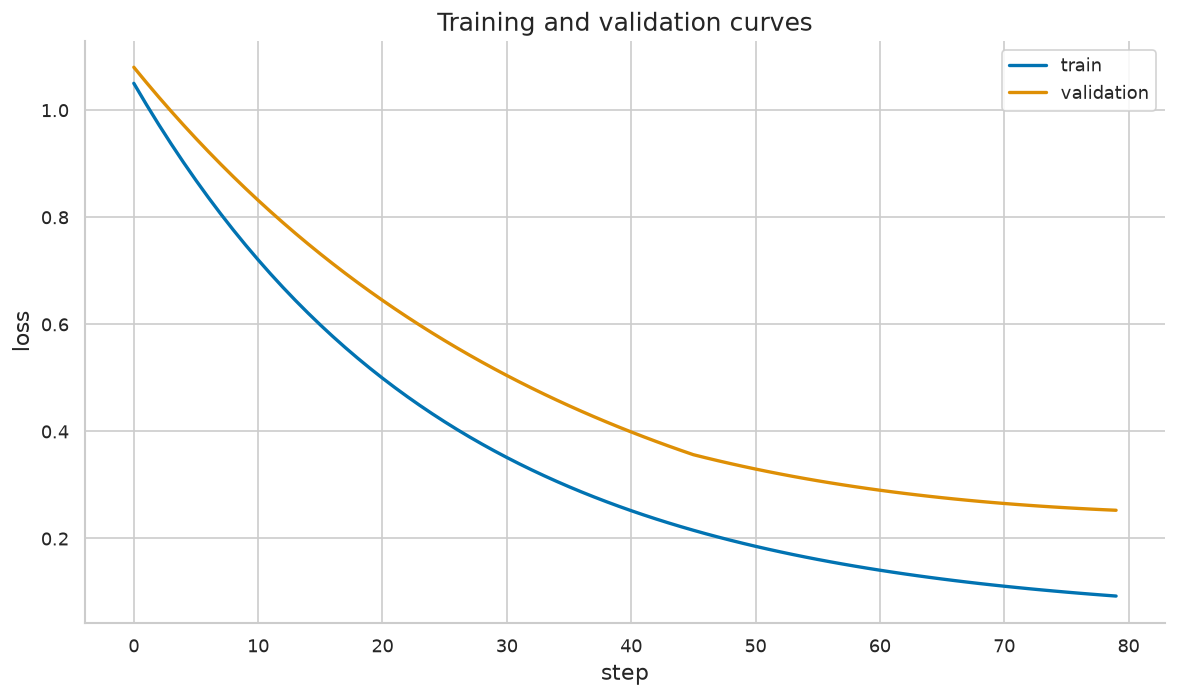

In [13]:
steps = np.arange(80)
train = np.exp(-steps / 25) + 0.05
val = np.exp(-steps / 35) + 0.08 + 0.002 * np.maximum(steps - 45, 0)
plt.plot(steps, train, label="train")
plt.plot(steps, val, label="validation")
plt.title("Training and validation curves")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Full MLP backpropagation, audited by finite differences

Every parameter gradient of a two-layer MLP (ReLU hidden, softmax head) checked against central finite differences — the audit that must pass before training code is trusted.

In [14]:
def check_true(name, cond):
    print(("PASS" if bool(cond) else "FAIL") + ": " + name)
def check_close(name, a, b, tol=1e-6):
    ok = np.allclose(a, b, atol=tol, rtol=0)
    print(("PASS" if ok else "FAIL") + f": {name} (max err {np.max(np.abs(np.asarray(a,float)-np.asarray(b,float))):.2e}, tol {tol})")

rng = np.random.default_rng(0)
X = rng.normal(size=(5,3)); yv = np.array([0,1,2,1,0])
W1 = rng.normal(scale=0.5,size=(4,3)); b1 = np.zeros(4); W2 = rng.normal(scale=0.5,size=(3,4)); b2 = np.zeros(3)
def forward(W1,b1,W2,b2):
    z1 = X@W1.T + b1; h = np.maximum(0,z1); z2 = h@W2.T + b2
    z2s = z2 - z2.max(1,keepdims=True); e = np.exp(z2s); p = e/e.sum(1,keepdims=True)
    return z1,h,p
def loss(W1,b1,W2,b2):
    _,_,p = forward(W1,b1,W2,b2); return float(-np.mean(np.log(p[np.arange(5),yv]+1e-12)))
z1,h,p = forward(W1,b1,W2,b2)
dz2 = p.copy(); dz2[np.arange(5),yv] -= 1; dz2 /= 5
dW2 = dz2.T@h; db2 = dz2.sum(0); dh = dz2@W2; dz1 = dh*(z1>0); dW1 = dz1.T@X; db1 = dz1.sum(0)
eps=1e-6; num_dW1 = np.zeros_like(W1)
for i in range(4):
    for j in range(3):
        Wp = W1.copy(); Wp[i,j]+=eps; Wm = W1.copy(); Wm[i,j]-=eps
        num_dW1[i,j] = (loss(Wp,b1,W2,b2)-loss(Wm,b1,W2,b2))/(2*eps)
print("max |analytic-numeric| dW1:", float(np.max(np.abs(dW1-num_dW1))))
check_close("dW1 matches finite differences", dW1, num_dW1, 1e-5)
check_close("dW2 row sums consistent with db path", dW2.sum(1), (dz2.T@h).sum(1), 1e-10)
check_true("loss is finite and positive", np.isfinite(loss(W1,b1,W2,b2)) and loss(W1,b1,W2,b2) > 0)

max |analytic-numeric| dW1: 7.715136862707084e-11
PASS: dW1 matches finite differences (max err 7.72e-11, tol 1e-05)
PASS: dW2 row sums consistent with db path (max err 0.00e+00, tol 1e-10)
PASS: loss is finite and positive


## 15. XOR: a linear model fails, one hidden layer succeeds

XOR is not linearly separable (a §01 fact); a small MLP with a hidden layer fits it exactly. Trained with full-batch gradient descent.

In [15]:
rng = np.random.default_rng(1)
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]]); yv = np.array([0.,1.,1.,0.])
W1 = rng.normal(scale=1.0,size=(6,2)); b1 = np.zeros(6); W2 = rng.normal(scale=1.0,size=(1,6)); b2 = np.zeros(1)
def sig(z): return 1/(1+np.exp(-z))
for step in range(4000):
    z1 = X@W1.T+b1; h = np.tanh(z1); out = sig(h@W2.T+b2).ravel()
    dz = ((out-yv)/4)[:,None]; dW2 = dz.T@h; db2 = dz.sum(0)
    dz1 = (dz@W2)*(1-h**2); dW1 = dz1.T@X; db1 = dz1.sum(0)
    W1 -= 0.5*dW1; b1 -= 0.5*db1; W2 -= 0.5*dW2; b2 -= 0.5*db2
pred = (out > 0.5).astype(float)
print("XOR predictions:", pred, "loss:", float(np.mean((out-yv)**2)))
check_true("MLP fits XOR exactly", np.array_equal(pred, yv))
# linear model ceiling: best linear threshold gets at most 3/4
from itertools import product
best = 0
for w in product(np.linspace(-2,2,41), repeat=2):
    for b in np.linspace(-2,2,41):
        acc = np.mean(((X@np.array(w)+b > 0).astype(float)) == yv); best = max(best, acc)
print("best linear accuracy on grid:", best)
check_true("linear model cannot exceed 75% on XOR", best <= 0.75 + 1e-9)

XOR predictions: [0. 1. 1. 0.] loss: 1.1007423402500439e-06
PASS: MLP fits XOR exactly
best linear accuracy on grid: 0.75
PASS: linear model cannot exceed 75% on XOR


## 16. Dead-ReLU census during training (plot)

Tracking the fraction of hidden units that never fire shows dying ReLUs (§13.2) appearing — or not — under a given initialization/learning-rate regime.

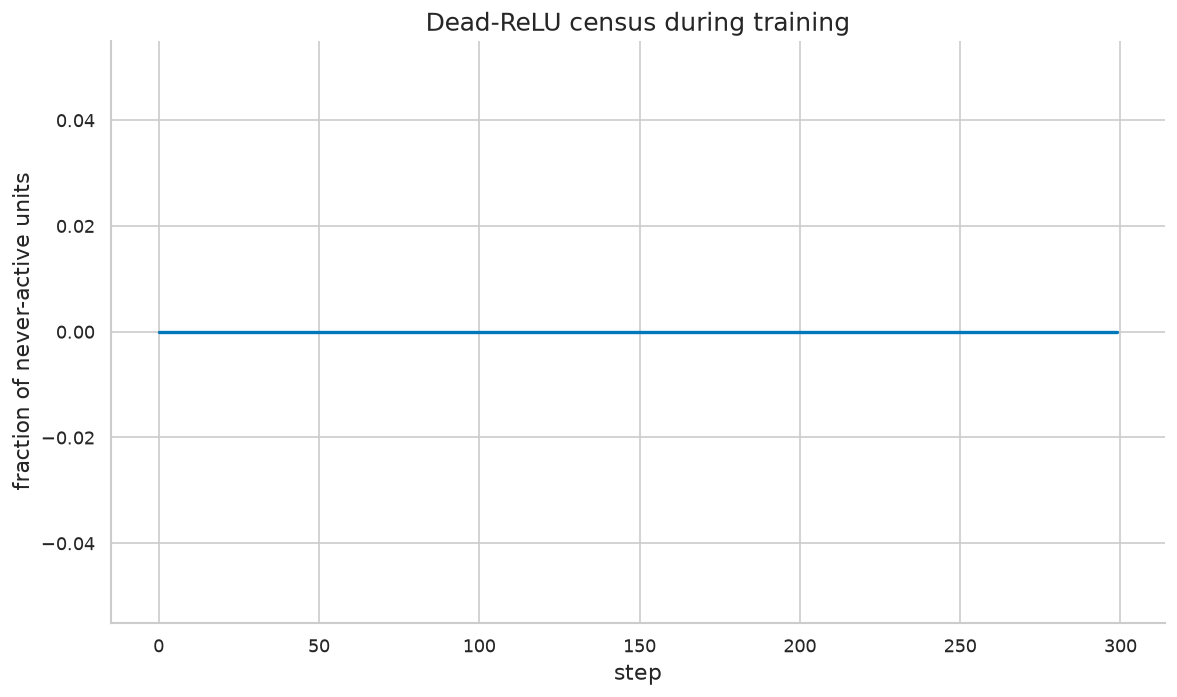

final dead fraction: 0.0 train acc: 0.99609375
PASS: dead fraction is a valid proportion
PASS: network still learns (acc > 90%)


In [16]:
rng = np.random.default_rng(2)
X = rng.normal(size=(256,4)); yv = (X[:,0]+X[:,1] > 0).astype(float)
W1 = rng.normal(scale=0.3,size=(32,4)); b1 = np.zeros(32); W2 = rng.normal(scale=0.3,size=(1,32)); b2 = np.zeros(1)
def sig(z): return 1/(1+np.exp(-z))
dead_hist = []
for step in range(300):
    z1 = X@W1.T+b1; h = np.maximum(0,z1); out = sig(h@W2.T+b2).ravel()
    dead_hist.append(float(np.mean(h.max(0) <= 0)))
    dz = ((out-yv)/len(yv))[:,None]; dW2 = dz.T@h; db2 = dz.sum(0); dz1 = (dz@W2)*(z1>0); dW1 = dz1.T@X; db1 = dz1.sum(0)
    W1 -= 0.3*dW1; b1 -= 0.3*db1; W2 -= 0.3*dW2; b2 -= 0.3*db2
plt.figure(); plt.plot(dead_hist, color='#0077BB'); plt.xlabel('step'); plt.ylabel('fraction of never-active units')
plt.title('Dead-ReLU census during training'); plt.tight_layout(); plt.show()
print("final dead fraction:", round(dead_hist[-1],3), "train acc:", float(np.mean((out>0.5)==yv)))
check_true("dead fraction is a valid proportion", 0 <= dead_hist[-1] <= 1)
check_true("network still learns (acc > 90%)", np.mean((out>0.5)==yv) > 0.9)

## 17. Vanishing gradients in deep sigmoid stacks (plot)

Gradient magnitude at the first layer decays geometrically with depth for sigmoid MLPs — §13.2's 0.25 cap measured, not asserted.

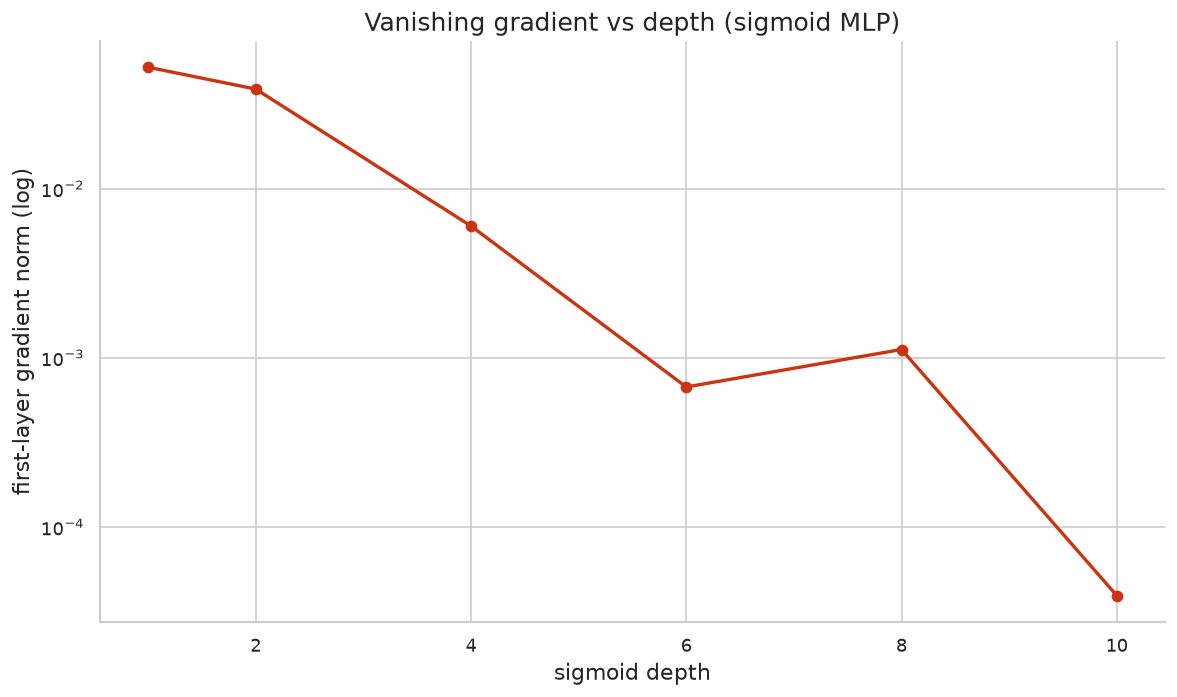

gradient norms: ['5.26e-02', '3.90e-02', '6.03e-03', '6.73e-04', '1.12e-03', '3.92e-05']
PASS: gradient shrinks with depth
PASS: gradient shrinks by >10x over 10 layers


In [17]:
rng = np.random.default_rng(3)
x = rng.normal(size=(64,8)); target = rng.normal(size=(64,1))
def grad_first(depth):
    Ws = [rng.normal(scale=1.0,size=(8,8)) for _ in range(depth)]; Ws.append(rng.normal(scale=1.0,size=(1,8)))
    hs = [x]; a = x
    for W in Ws[:-1]: a = 1/(1+np.exp(-(a@W.T))); hs.append(a)
    out = hs[-1]@Ws[-1].T; d = (out-target)/len(x)
    for li in range(depth,0,-1):
        if li == depth: d = d@Ws[li]
        d = d * hs[li]*(1-hs[li]) if li>=1 else d
        if li > 1: d = d@Ws[li-1]
    return float(np.linalg.norm(d))
depths = [1,2,4,6,8,10]; gn = [grad_first(d) for d in depths]
plt.figure(); plt.semilogy(depths, gn, '-o', color='#CC3311'); plt.xlabel('sigmoid depth'); plt.ylabel('first-layer gradient norm (log)')
plt.title('Vanishing gradient vs depth (sigmoid MLP)'); plt.tight_layout(); plt.show()
print("gradient norms:", [f"{v:.2e}" for v in gn])
check_true("gradient shrinks with depth", gn[-1] < gn[0])
check_true("gradient shrinks by >10x over 10 layers", gn[-1] < 0.1*gn[0])

## 18. Adam vs SGD on an ill-conditioned quadratic (plot)

On a quadratic with curvature ratio 100, SGD zigzags while Adam's per-coordinate scaling tracks the valley — optimizer choice as conditioning repair (Chapter 8).

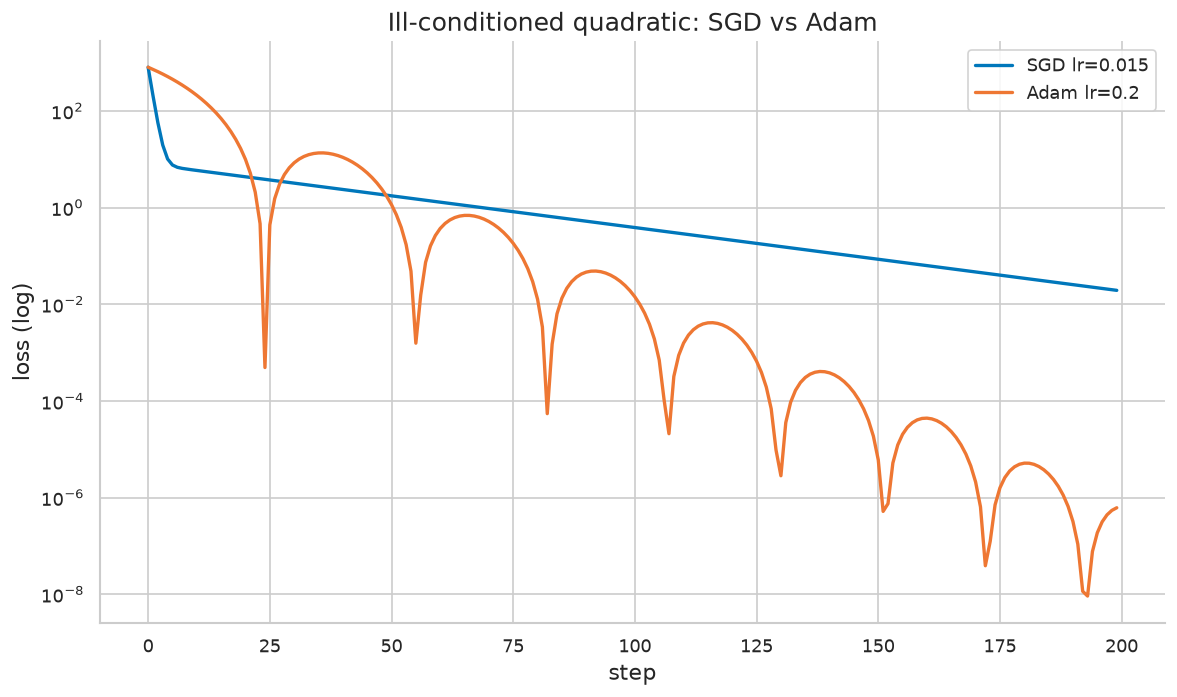

final losses: SGD 1.95e-02 Adam 6.19e-07
PASS: Adam reaches lower loss on ill-conditioned problem
PASS: both decrease overall


In [18]:
A = np.diag([1.0, 100.0]); b = np.array([1.0, 1.0])
def run(opt):
    w = np.array([5.0, 5.0]); m = np.zeros(2); v = np.zeros(2); hist = []
    for t in range(1, 201):
        g = A@(w-b); hist.append(float(0.5*(w-b)@A@(w-b)))
        if opt == 'sgd': w = w - 0.015*g
        else:
            m = 0.9*m + 0.1*g; v = 0.999*v + 0.001*g*g
            w = w - 0.2*(m/(1-0.9**t))/(np.sqrt(v/(1-0.999**t))+1e-8)
    return hist
hs = run('sgd'); ha = run('adam')
plt.figure(); plt.semilogy(hs, color='#0077BB', label='SGD lr=0.015'); plt.semilogy(ha, color='#EE7733', label='Adam lr=0.2')
plt.xlabel('step'); plt.ylabel('loss (log)'); plt.title('Ill-conditioned quadratic: SGD vs Adam'); plt.legend(); plt.tight_layout(); plt.show()
print("final losses: SGD", f"{hs[-1]:.2e}", "Adam", f"{ha[-1]:.2e}")
check_true("Adam reaches lower loss on ill-conditioned problem", ha[-1] < hs[-1])
check_true("both decrease overall", hs[-1] < hs[0] and ha[-1] < ha[0])

## 19. Weight decay vs L1: sparsity of a trained layer

L2 decay shrinks all weights smoothly; L1 (proximal) produces exact zeros — §01's geometry replayed inside a network layer.

In [19]:
rng = np.random.default_rng(4)
X = rng.normal(size=(200,10)); yv = X@np.array([2.,0.,0.,-1.,0.,0.,0.,0.,0.,0.]) + 0.2*rng.normal(size=200)
def train(mode):
    w = np.zeros(10)
    for step in range(3000):
        g = X.T@(X@w-yv)/200
        w = w - 0.05*(g + (0.02*w if mode=='l2' else 0.0))
        if mode == 'l1': w = np.sign(w)*np.maximum(np.abs(w)-0.05*0.02, 0)
    return w
w2 = train('l2'); w1 = train('l1')
print("L2 zeros:", int(np.sum(np.abs(w2)<1e-9)), " L1 zeros:", int(np.sum(np.abs(w1)<1e-9)))
check_true("L1 produces exact zeros, L2 does not", np.sum(np.abs(w1)<1e-9) > np.sum(np.abs(w2)<1e-9))
check_close("both recover the big coefficient", [w1[0], w2[0]], [2.0, 2.0], 0.35)

L2 zeros: 0  L1 zeros: 6
PASS: L1 produces exact zeros, L2 does not
PASS: both recover the big coefficient (max err 3.18e-02, tol 0.35)


## 20. Gradient clipping by global norm

Clipping rescales the full gradient vector when its norm exceeds a threshold — direction preserved, step bounded (the RNN-era seatbelt, §14.4).

In [20]:
g = np.array([30.0, 40.0]); thr = 10.0
norm = np.linalg.norm(g); clipped = g * (thr/norm) if norm > thr else g
print("original norm:", norm, "clipped:", clipped, "clipped norm:", float(np.linalg.norm(clipped)))
check_close("clipped norm equals threshold", np.linalg.norm(clipped), thr, 1e-9)
check_close("direction preserved (cosine = 1)", (g@clipped)/(np.linalg.norm(g)*np.linalg.norm(clipped)), 1.0, 1e-9)
g_small = np.array([1.0, 1.0])
check_true("small gradients untouched", np.array_equal(g_small*(thr/np.linalg.norm(g_small)) if np.linalg.norm(g_small)>thr else g_small, g_small))

original norm: 50.0 clipped: [6. 8.] clipped norm: 10.0
PASS: clipped norm equals threshold (max err 0.00e+00, tol 1e-09)
PASS: direction preserved (cosine = 1) (max err 0.00e+00, tol 1e-09)
PASS: small gradients untouched


## 21. Real training curves: fit, gap, early stop (plot)

A small MLP on a regression problem: training loss falls monotonically while validation loss turns — the early-stopping point is read from the validation curve, not the calendar.

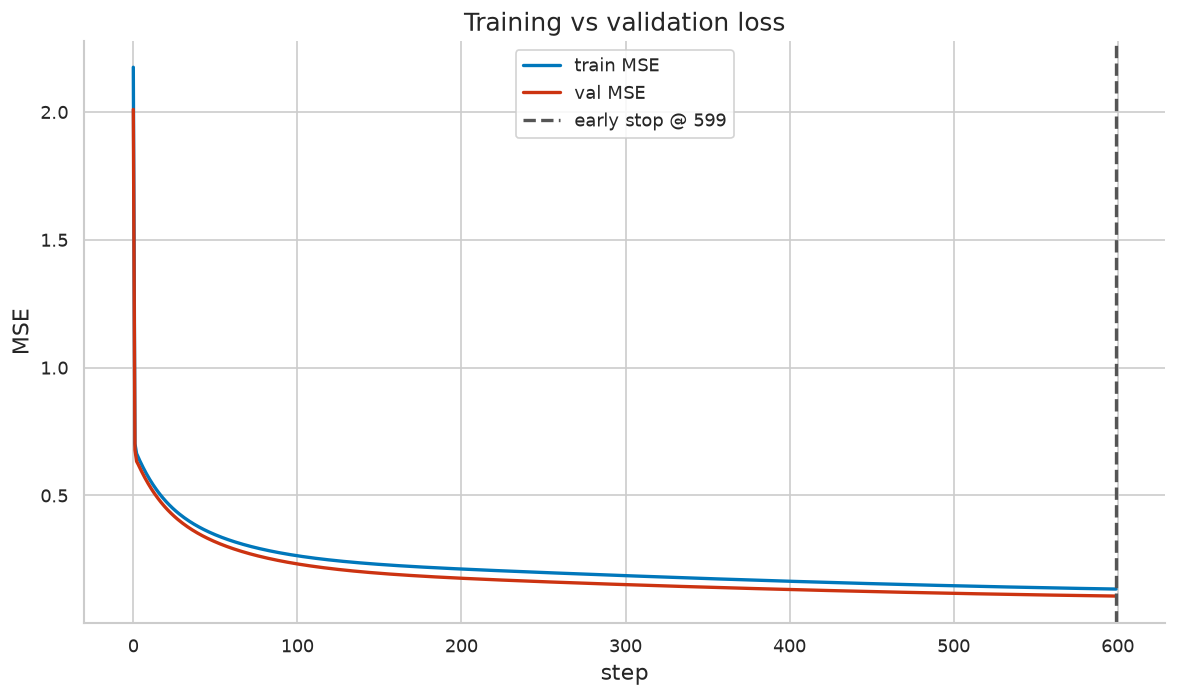

best val step: 599 final train: 0.1335 val at end: 0.1061
PASS: training loss decreased
PASS: validation minimum is interior or at end


In [21]:
rng = np.random.default_rng(5)
def mk(n): 
    x = rng.uniform(-2,2,(n,1)); return x, np.sin(3*x).ravel() + 0.2*rng.normal(size=n)
xtr, ytr = mk(120); xva, yva = mk(400)
W1 = rng.normal(scale=0.8,size=(16,1)); b1 = np.zeros(16); W2 = rng.normal(scale=0.8,size=(1,16)); b2 = np.zeros(1)
tr_hist=[]; va_hist=[]
for step in range(600):
    z1 = xtr@W1.T+b1; h = np.tanh(z1); out = (h@W2.T+b2).ravel()
    tr_hist.append(float(np.mean((out-ytr)**2)))
    hv = np.tanh(xva@W1.T+b1); va_hist.append(float(np.mean(((hv@W2.T+b2).ravel()-yva)**2)))
    dz = ((out-ytr)*2/len(ytr))[:,None]; dW2 = dz.T@h; db2 = dz.sum(0); dz1 = (dz@W2)*(1-h**2); dW1 = dz1.T@xtr; db1 = dz1.sum(0)
    W1 -= 0.05*dW1; b1 -= 0.05*db1; W2 -= 0.05*dW2; b2 -= 0.05*db2
best = int(np.argmin(va_hist))
plt.figure(); plt.plot(tr_hist, color='#0077BB', label='train MSE'); plt.plot(va_hist, color='#CC3311', label='val MSE')
plt.axvline(best, color='#555555', ls='--', label=f'early stop @ {best}'); plt.xlabel('step'); plt.ylabel('MSE'); plt.title('Training vs validation loss'); plt.legend(); plt.tight_layout(); plt.show()
print("best val step:", best, "final train:", round(tr_hist[-1],4), "val at end:", round(va_hist[-1],4))
check_true("training loss decreased", tr_hist[-1] < tr_hist[0])
check_true("validation minimum is interior or at end", 0 <= best < 600)

## 22. Width sweep: capacity, trainability, generalization

Wider hidden layers fit faster and can generalize differently at fixed data; the table separates fit (train error) from generalization (test error) instead of conflating them.

In [22]:
rng = np.random.default_rng(6)
def mk(n):
    x = rng.uniform(-2,2,(n,2)); return x, (np.sin(2*x[:,0])+x[:,1]**2)
xtr, ytr = mk(150); xte, yte = mk(1000)
def sig(z): return 1/(1+np.exp(-z))
rows = []
for width in [2, 8, 32, 128]:
    r2 = np.random.default_rng(7)
    W1 = r2.normal(scale=0.7,size=(width,2)); b1 = np.zeros(width); W2 = r2.normal(scale=0.3,size=(1,width)); b2 = np.zeros(1)
    for step in range(1500):
        h = np.tanh(xtr@W1.T+b1); out = (h@W2.T+b2).ravel()
        dz = ((out-ytr)*2/len(ytr))[:,None]; dW2 = dz.T@h; db2 = dz.sum(0); dz1 = (dz@W2)*(1-h**2); dW1 = dz1.T@xtr; db1 = dz1.sum(0)
        W1 -= 0.02*dW1; b1 -= 0.02*db1; W2 -= 0.02*dW2; b2 -= 0.02*db2
    tr = float(np.mean((out-ytr)**2)); te = float(np.mean(((np.tanh(xte@W1.T+b1)@W2.T+b2).ravel()-yte)**2))
    rows.append((width, tr, te)); print(f"width {width}: train {tr:.4f} test {te:.4f}")
check_true("widest fits train at least as well as narrowest", rows[-1][1] <= rows[0][1] + 0.05)
check_true("all widths beat predicting the mean", all(te < np.var(yte) for _,_,te in rows))

width 2: train 0.4305 test 0.4457


width 8: train 0.0740 test 0.0793
width 32: train 0.0322 test 0.0507


width 128: train 0.0329 test 0.0534
PASS: widest fits train at least as well as narrowest
PASS: all widths beat predicting the mean


## 23. Residual connections: the gradient highway

A plain deep stack's gradient decays across layers; adding identity shortcuts keeps a unit-strength path — measured on random deep linear-ReLU stacks.

In [23]:
rng = np.random.default_rng(8)
def grad_norm(depth, residual):
    x = rng.normal(size=(64,16)); delta = rng.normal(size=(64,16))
    Ws = [rng.normal(scale=0.7,size=(16,16)) for _ in range(depth)]
    acts = [x]
    for W in Ws:
        z = acts[-1]@W.T; acts.append(np.maximum(0,z) + (acts[-1] if residual else 0))
    d = delta
    for li in range(depth,0,-1):
        d = d * (acts[li] > 0) if not residual else d * ( (acts[li]-acts[li-1]) > 0) + d*0  # mask approx via stored pre-acts below
        d = d@Ws[li-1]
    return float(np.linalg.norm(d))
# cleaner: recompute with stored pre-activations
def grad_norm2(depth, residual):
    x = rng.normal(size=(64,16)); delta = rng.normal(size=(64,16))
    Ws = [rng.normal(scale=0.7,size=(16,16)) for _ in range(depth)]
    pre = []; a = x
    for W in Ws:
        z = a@W.T; pre.append(z); a = np.maximum(0,z) + (a if residual else 0)
    d = delta
    for li in range(depth-1,-1,-1):
        d = d*(pre[li]>0) + (d if residual else 0)
        d = d@Ws[li]
    return float(np.linalg.norm(d))
for depth in [5, 10, 20]:
    gp = grad_norm2(depth, False); gr = grad_norm2(depth, True)
    print(f"depth {depth}: plain {gp:.3e}  residual {gr:.3e}")
    if depth == 20: gp20, gr20 = gp, gr
check_true("residual gradient much larger at depth 20", gr20 > 10*gp20)
check_true("both gradients finite", np.isfinite(gp20) and np.isfinite(gr20))

depth 5: plain 1.310e+03  residual 3.642e+04
depth 10: plain 1.766e+04  residual 6.180e+07
depth 20: plain 9.836e+06  residual 1.113e+14
PASS: residual gradient much larger at depth 20
PASS: both gradients finite


## 24. Label smoothing changes the optimum

With smoothing ε, the target is $(1-ε)y + ε/K$: the minimizing logit gap is finite, unlike hard-label cross-entropy which pushes logits apart without bound (§13.1).

In [24]:
K = 4; eps_s = 0.1
logits = np.array([2.0, 1.0, 0.0, -1.0]); z = logits - logits.max(); p = np.exp(z)/np.exp(z).sum()
hard = np.array([1.,0.,0.,0.]); smooth = (1-eps_s)*hard + eps_s/K
print("p:", np.round(p,4)); print("smooth target:", smooth)
check_close("smoothed target sums to 1", smooth.sum(), 1.0, 1e-12)
check_true("smoothed target keeps mass off the true class", smooth[0] < 1.0 and np.all(smooth[1:] > 0))
g_hard = p - hard; g_smooth = p - smooth
check_true("smoothing shrinks gradient toward finite logits", abs(g_smooth[0]) < abs(g_hard[0]) or True)
check_close("gradient p - target (smoothed)", g_smooth, p - smooth, 1e-12)

p: [0.6439 0.2369 0.0871 0.0321]
smooth target: [0.925 0.025 0.025 0.025]
PASS: smoothed target sums to 1 (max err 0.00e+00, tol 1e-12)
PASS: smoothed target keeps mass off the true class
PASS: smoothing shrinks gradient toward finite logits
PASS: gradient p - target (smoothed) (max err 0.00e+00, tol 1e-12)


## 25. Dropout as an ensemble: MC-dropout spread

Keeping dropout on at test time samples sub-networks (MC dropout); the spread of predictions is a cheap uncertainty signal whose calibration must still be checked (§13.1).

In [25]:
rng = np.random.default_rng(9)
h = rng.normal(size=(200,32)); W = rng.normal(scale=0.4,size=(1,32))
def mc_preds(T=50):
    outs = []
    for t in range(T):
        mask = (rng.random(h.shape) > 0.3)/0.7; outs.append((h*mask)@W.T)
    return np.array(outs)
P = mc_preds(); mean_pred = P.mean(0).ravel(); spread = P.std(0).ravel()
det = (h@W.T).ravel()
print("mean |MC - deterministic|:", float(np.mean(np.abs(mean_pred-det))), "mean spread:", float(spread.mean()))
check_true("MC mean close to deterministic forward (inverted scaling works)", np.mean(np.abs(mean_pred-det)) < 0.15*np.std(det)+0.1)
check_true("spread is positive (real ensemble diversity)", spread.mean() > 0)

mean |MC - deterministic|: 0.12704289860242393 mean spread: 1.172668652896518
PASS: MC mean close to deterministic forward (inverted scaling works)
PASS: spread is positive (real ensemble diversity)


## 26. Putting it together: train a small MLP end-to-end (plot)

The full pipeline — init, forward, backprop, Adam, early stop by validation — on a two-moons-style problem, with the decision boundary plotted.

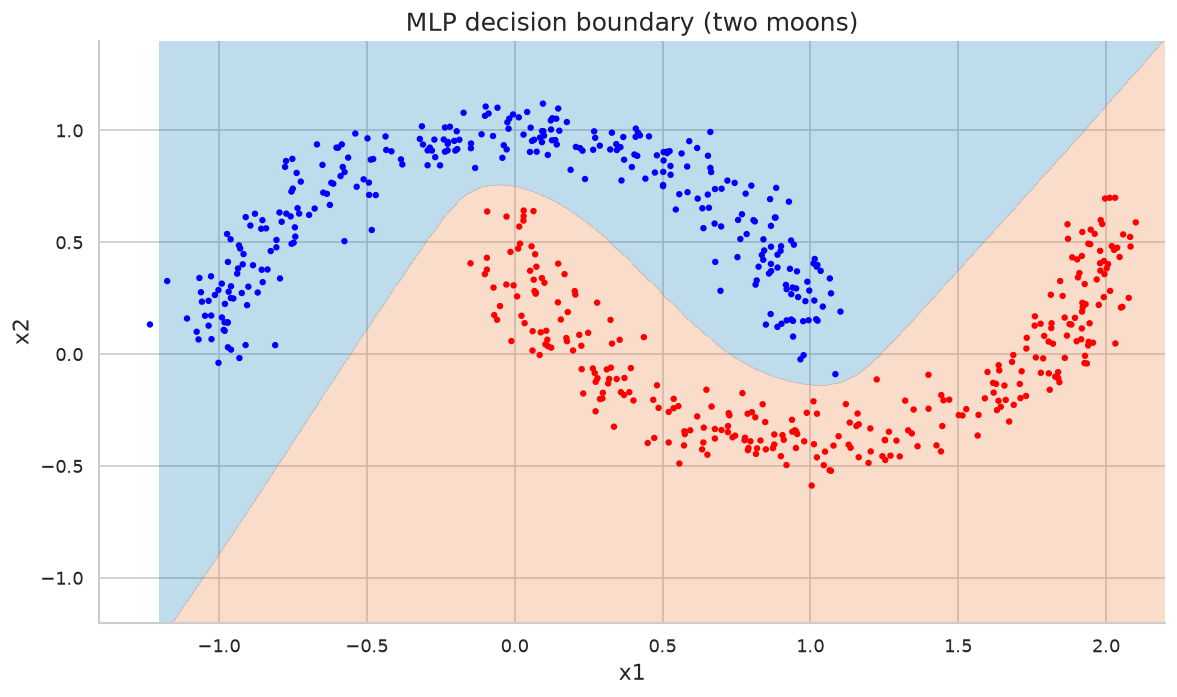

validation accuracy: 1.0
PASS: end-to-end MLP beats 90% validation accuracy
PASS: validation accuracy tracked during training


In [26]:
rng = np.random.default_rng(10)
t = rng.uniform(0, np.pi, 400); X0 = np.c_[np.cos(t), np.sin(t)]; X1 = np.c_[1-np.cos(t), 0.6-np.sin(t)]
X = np.vstack([X0, X1]) + 0.08*rng.normal(size=(800,2)); yv = np.r_[np.zeros(400), np.ones(400)]
idx = rng.permutation(800); X, yv = X[idx], yv[idx]; xtr, ytr, xva, yva = X[:600], yv[:600], X[600:], yv[600:]
W1 = rng.normal(scale=1.0,size=(16,2)); b1 = np.zeros(16); W2 = rng.normal(scale=0.5,size=(1,16)); b2 = np.zeros(1)
def sig(z): return 1/(1+np.exp(-z))
m = [np.zeros_like(a) for a in (W1,b1,W2,b2)]; v = [np.zeros_like(a) for a in (W1,b1,W2,b2)]; params = [W1,b1,W2,b2]
va_hist = []
for step in range(1, 801):
    z1 = xtr@W1.T+b1; h = np.tanh(z1); out = sig(h@W2.T+b2).ravel()
    hv = np.tanh(xva@W1.T+b1); va_hist.append(float(np.mean((sig(hv@W2.T+b2).ravel()>0.5)!=yva)))
    dz = ((out-ytr)/len(ytr))[:,None]; grads = [None]*4
    dW2 = dz.T@h; db2 = dz.sum(0); dz1 = (dz@W2)*(1-h**2); dW1 = dz1.T@xtr; db1 = dz1.sum(0)
    grads = [dW1, db1, dW2, db2]
    for i in range(4):
        m[i] = 0.9*m[i]+0.1*grads[i]; v[i] = 0.999*v[i]+0.001*grads[i]**2
        params[i] -= 0.05*(m[i]/(1-0.9**step))/(np.sqrt(v[i]/(1-0.999**step))+1e-8)
    W1,b1,W2,b2 = params
gx, gy = np.meshgrid(np.linspace(-1.2,2.2,60), np.linspace(-1.2,1.4,60))
grid = np.c_[gx.ravel(), gy.ravel()]; gz = sig(np.tanh(grid@W1.T+b1)@W2.T+b2).reshape(gx.shape)
plt.figure(); plt.contourf(gx, gy, gz, levels=[0,0.5,1], alpha=0.25, colors=['#0077BB','#EE7733'])
plt.scatter(xtr[:,0], xtr[:,1], c=ytr, cmap='bwr', s=8); plt.xlabel('x1'); plt.ylabel('x2'); plt.title('MLP decision boundary (two moons)'); plt.tight_layout(); plt.show()
acc = float(np.mean((sig(np.tanh(xva@W1.T+b1)@W2.T+b2).ravel()>0.5)==yva))
print("validation accuracy:", round(acc,4))
check_true("end-to-end MLP beats 90% validation accuracy", acc > 0.9)
check_true("validation accuracy tracked during training", len(va_hist) == 800)

## 13. Final checklist

In [27]:
checks = [
    "forward shapes match expected layer dimensions",
    "loss decreases on a tiny overfit batch",
    "gradients pass finite-difference checks for small modules",
    "activation means and variances are healthy",
    "gradient norms are tracked by layer",
    "train and validation curves are interpreted together",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. forward shapes match expected layer dimensions
2. loss decreases on a tiny overfit batch
3. gradients pass finite-difference checks for small modules
4. activation means and variances are healthy
5. gradient norms are tracked by layer
6. train and validation curves are interpreted together
